# TSARA, Phase 3.6 — clocks

**A walkthrough you can run, change and try to break.** Every number and figure
below is produced by the package from air the generator manufactures, with
every plume it injected and every clock error it wrote recorded, so the right
answer is always known. No real measurement is read, and nothing needs
mounting.

---

## How to use this notebook

1. **Run everything once** (*Run All*, about a minute).
2. **Every section stands on its own.** Each opens with a **parameters cell**:
   a short list of CAPITALISED names, each commented with what it controls.
   Change a value, then run that section's cells from the parameters cell down
   to the next heading. Sections share only the setup cell below.
3. **Sections §2 to §6 print checks** (§1 uses TSARA only to generate air, so it has none). A
   line beginning ✔ is a claim about TSARA,
   compared *as it ran* against something written independently in this
   notebook: a plain loop written from the definition, or the shift the
   archive was written to need. The checks are written to hold at *any*
   parameters. If you ever see ✘, you have found an edge case worth
   understanding or a bug.
4. **"Try it"** notes after each section suggest a change and say what should
   happen. Each prediction was run before this notebook was committed.
5. **The last section** collects every check into one scoreboard.

---

## What this phase delivers

Phase 3.5 settled *what interval* of air each value describes. This phase
settles *when*: how one instrument's clock relates to another's, how that is
measured from the data, and how a correction is declared and applied
(`METHODS.md` §12).

| | Property | Section |
|---|---|---|
| 1 | **A clock error costs a fit within seconds**: two analyzers of one gas, per-plume fits as one is moved | §1 |
| 2 | **A correction table**, declared beside the manifest and applied to each file as it is read | §2 |
| 3 | **One segment's shift**, from the plumes two instruments share | §3 |
| 4 | **The survey**: every segment, the chain to one reference clock, the rows of a table | §4 |
| 5 | **What it names instead of fitting**: a drift, an outlier, an undecided stretch | §5 |
| 6 | **The loop closed**: the survey's own table applied, and surveyed again | §6 |

What this phase does **not** do: read a real campaign (that is the SLC-SOS
work that follows), or measure anything but clocks (a precision, a
decorrelation time) — the survey is built so those can join it later.

---

## Vocabulary used throughout

| term | meaning |
|---|---|
| **reading** | one value an instrument wrote, with the interval of air it describes |
| **recorded clock** | the time a file wrote beside each reading, right or wrong |
| **shift** | the one clock number: seconds *added* to a reading's recorded time to correct it, **corrected = recorded + shift**, the sign rule of `time_shift`. A file that shows the air 5 s late takes −5 s, one 4 s early +4 s. The archive's clock errors, the correction table and the survey all write shifts, so they can be compared number for number |
| **reference clock** | the clock every instrument is put on, named by the instrument that keeps it |
| **correction table** | a CSV of rows, each a stretch of one instrument on its recorded clock and the shift that puts it on the reference clock (`Manifest.clock_corrections`) |
| **tracer pair** | a variable on each of two instruments expected to show the same plumes: one gas on two analyzers, or gases emitted together |
| **tier** | an instrument's tracer pairs are ranked; the first tier that decides a segment sets its shift, the others check it |
| **segment** | a contiguous stretch of a record; the survey measures one shift on each |
| **wiggles** | a variable minus its centred running median: its plumes without the slow background |
| **resolution** | the step a shift is measured in: a whole second by default, finer when asked (`METHODS.md` §12.4) |
| **clock step**, **clock drift** | a shift that jumps between segments, and one that changes steadily across a stretch |
| **survey** | `tsara.survey`: measures what a manifest can declare but files do not state, and writes a table a person reviews. Never applied by itself |

---
## Setup (run this cell first)

The **toolkit**: imports, the figure style shared by notebooks 01–08, the
**reference implementations** the checks compare TSARA against, the
scoreboard, and the **recipes** that manufacture air and write it on wrong
clocks.

In [1]:
# =============================================================================
# TOOLKIT. Every section needs this cell and nothing else from other sections.
# =============================================================================
import logging
import tempfile
from dataclasses import asdict
from functools import cache
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from tsara import setup_logging
from tsara.config.loader import load_manifest
from tsara.config.survey import SurveyConfig
from tsara.config.synthetic import SyntheticConfig
from tsara.core.clocks import read_clock_corrections, shift_at, write_clock_corrections
from tsara.core.support import CellBounds
from tsara.ingest import ingest_campaign
from tsara.survey import (
    FAULT_KINDS,
    load_clock_survey,
    pooled_shift,
    save_clock_survey,
    seconds_series,
    survey_clocks,
)
from tsara.survey.shifts import cell_series, refined_shift
from tsara.synthetic import generate
from tsara.synthetic.export import ClockError, export_raw

# --- 1. figure style (identical to notebooks 01-07) --------------------------
C1, C2, C3 = "#0072b2", "#e69f00", "#009e73"  # Okabe-Ito blue, amber, green: colour-blind safe
C4 = "#cc79a7"  # Okabe-Ito purple, for a fourth series
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, SURFACE = "#e1e0d9", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "normal",
        "axes.titlelocation": "left",
        "axes.labelsize": 9.5,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelsize": 8.5,
        "ytick.labelsize": 8.5,
        "grid.color": GRID,
        "grid.linewidth": 0.7,
        "grid.linestyle": "-",
        "legend.frameon": False,
        "legend.fontsize": 9,
        "font.size": 9.5,
        "lines.linewidth": 1.4,
        "figure.dpi": 110,
    }
)


def finish(
    ax, title=None, sub=None, ylab=None, xlab=None, legend=False, grid_axis="y", loc="upper right"
):
    """Apply the shared chrome: left-aligned title, muted subtitle, hairline grid."""
    if title:
        ax.set_title(title, pad=19 if sub else 8)
    if sub:
        ax.text(0, 1.025, sub, transform=ax.transAxes, fontsize=8.8, color=MUTED, va="bottom")
    if ylab:
        ax.set_ylabel(ylab)
    if xlab:
        ax.set_xlabel(xlab)
    if grid_axis:
        ax.grid(True, axis=grid_axis, alpha=0.9)
    ax.set_axisbelow(True)
    if legend:
        ax.legend(loc=loc)


def clock(ax, fmt="%H:%M"):
    """Label a time axis in hours and minutes, or in the format given."""
    ax.xaxis.set_major_formatter(mdates.DateFormatter(fmt))


# --- 2. reference implementations --------------------------------------------
# Written from the definitions, deliberately slow and plain, one value at a
# time. They share no code with TSARA. If TSARA and these agree, it is because
# both compute the definition (METHODS.md §12.4).


def reference_wiggles(stream, variable, window_s):
    """Return a variable on whole seconds minus its centred running median, by plain loops.

    Whole seconds: each timestamp floored, the first reading of each second
    kept. The median at a second is over the readings within window/2 of it,
    used when at least a quarter of the window's possible readings are there
    (and at least three). Returns {second: wiggle}.
    """
    times = stream["time"].values.astype("datetime64[ns]").astype("int64")
    values = stream[variable].values
    kept = {}
    for t, v in zip(times, values):
        second = int(t // 1_000_000_000)
        if np.isfinite(v) and second not in kept:
            kept[second] = float(v)
    seconds = sorted(kept)
    spacing = float(np.median(np.diff(seconds)))
    need = max(3, int(0.25 * window_s / spacing))
    half = window_s / 2
    out = {}
    for s in seconds:
        near = [kept[u] for u in seconds if abs(u - s) <= half]
        if len(near) >= need:
            out[s] = kept[s] - float(np.median(near))
    return out


def reference_shift(own, partner, first_s, stop_s, search_s, min_pairs):
    """Return the best shift of one segment by plain loops: own(t) against partner(t + s).

    The shift s puts own's times on partner's clock: what own records at t,
    partner records at t + s. Returns (shift, r) at the s in [-search, search]
    with the largest Pearson r over at least min_pairs paired seconds.
    """
    best = (None, -np.inf)
    for shift in range(-search_s, search_s + 1):
        x, y = [], []
        for t in range(first_s, stop_s):
            if t in own and (t + shift) in partner:
                x.append(own[t])
                y.append(partner[t + shift])
        if len(x) >= min_pairs:
            r = float(np.corrcoef(x, y)[0, 1])
            if r > best[1]:
                best = (shift, r)
    return best


# --- 3. the scoreboard -------------------------------------------------------
CHECKS = {}


def start_section(tag):
    """Forget a section's earlier checks, so re-running it replaces rather than piles up."""
    for claim in [c for c in CHECKS if c.startswith(tag + " ")]:
        del CHECKS[claim]


def check(claim, holds, detail=""):
    """Record one claim about TSARA and print whether it held just now."""
    CHECKS[claim] = (bool(holds), detail)
    mark = "✔" if holds else "✘ DOES NOT HOLD:"
    print(f"  {mark} {claim}" + (f"   [{detail}]" if detail else ""))


# --- 4. recipes ---------------------------------------------------------------
START = pd.Timestamp("2026-01-01T00:00:00")


@cache
def campaign(seed=11, duration="150min", plumes_per_hour=40.0, plume_sigma="4s"):
    """Generate three methane analyzers seeing the same plumes.

    'ref' (1 s, the reference clock), 'fast' (1 s) and 'slow' (2 s), each with
    its own noise. Cached: sections that ask for the same air share it.
    """

    def analyzer(rate, sigma):
        return {
            "native_rate": rate,
            "measures": {"ch4": {"uncertainty": {"random": {"absolute": sigma}}}},
        }

    config = SyntheticConfig.model_validate(
        {
            "name": "clocks",
            "start": "2026-01-01T00:00:00Z",
            "duration": duration,
            "seed": seed,
            "platform": {"kind": "stationary", "latitude": 40.0, "longitude": -111.0},
            "atmosphere": {
                "fields": {
                    "ch4": {"units": "ppb", "background": {"kind": "parametric", "offset": 1950.0}}
                },
                "sources": {
                    "street": {
                        "rate_per_hour": plumes_per_hour,
                        "reference_species": "ch4",
                        "shape": {"kind": "gaussian", "sigma": plume_sigma},
                        "amplitude": {"kind": "lognormal", "median": 80.0, "sigma_log": 0.6},
                    }
                },
            },
            "instruments": {
                "ref": analyzer("1s", 1.0),
                "fast": analyzer("1s", 2.0),
                "slow": analyzer("2s", 1.5),
            },
        }
    )
    return generate(config)


@cache
def archive(shifts, seed=11, duration="150min"):
    """Write a campaign's files on wrong clocks, with the table that would undo them.

    ``shifts`` is a tuple of (instrument, start, end, shift): each stretch is
    written on a clock that the shift corrects, so a clock 7 s ahead is -7.
    Returns (dataset, manifest without the table, path of the exporter's own
    table, which holds the same shifts).
    """
    dataset = campaign(seed=seed, duration=duration)
    clock_errors = {}
    for name, start, end, shift in shifts:
        clock_errors.setdefault(name, []).append(ClockError(start, end, f"{shift}s"))
    folder = Path(tempfile.mkdtemp()) / "archive"
    manifest = load_manifest(
        export_raw(dataset, folder, clock_errors=clock_errors, reference_clock="ref")
    )
    truth_table = manifest.clock_corrections[0]
    return dataset, manifest.model_copy(update={"clock_corrections": ()}), truth_table


def survey_settings(segment="30min", min_r=0.6, tolerance="2s", **more):
    """Return survey settings for the three analyzers.

    'fast' is measured against 'ref'; 'slow' against 'fast' first and 'ref' as a backup.
    """
    return SurveyConfig.model_validate(
        {
            "reference_clock": "ref",
            "segment": segment,
            "min_r": min_r,
            "tolerance": tolerance,
            "tracers": {
                "fast": [{"partner": "ref", "pairs": [["ch4", "ch4"]]}],
                "slow": [
                    {"partner": "fast", "pairs": [["ch4", "ch4"]]},
                    {"partner": "ref", "pairs": [["ch4", "ch4"]]},
                ],
            },
            **more,
        }
    )


def shift_panel(ax, survey, name, truth=None, color=C1):
    """Plot each segment's shift onto the reference clock, the rows written, and the truth.

    Points: decided segments; a cross: one set aside as an outlier; grey: a
    segment with readings but no decision, left uncorrected; solid lines: the
    rows the survey wrote (a drift row slopes); dashed: the shift the readings
    were written to need.
    """
    seg = survey.segments[survey.segments.instrument == name]
    width = pd.Timedelta(survey.config.segment)
    start = pd.to_datetime(seg.start).dt.tz_localize(None)
    mid = start + width / 2
    shifts = seg.shift_onto_reference_s
    decided = seg.status == "decided"
    ax.plot(mid[decided], shifts[decided], "o", color=color, ms=6, label="a segment's shift")
    odd = seg.status == "outlier"
    if odd.any():
        ax.plot(mid[odd], shifts[odd], "X", color=C4, ms=9, label="set aside: outlier")
    none = ~seg.status.isin(["decided", "outlier", "too short"])
    for first in start[none]:
        ax.axvspan(first, first + width, color=GRID, lw=0, zorder=0)
    if none.any():
        ax.fill_between([], [], color=GRID, label="no decision")
    values = list(shifts.dropna())
    for i, row in enumerate(r for r in survey.rows if r.instrument == name):
        ends = [pd.Timestamp(row.start_ns), pd.Timestamp(row.end_ns)]
        written = [row.shift_ns, row.shift_end_ns if row.shift_end_ns is not None else row.shift_ns]
        ax.plot(
            ends,
            [v / 1e9 for v in written],
            color=INK,
            lw=2.4,
            alpha=0.45,
            label="the rows written" if i == 0 else None,
            solid_capstyle="butt",
        )
        values += [v / 1e9 for v in written]
    if truth is not None:
        ax.plot(truth.index, truth.values, color=INK2, lw=1, ls="--", label="the shift written")
        values += list(truth.values)
    ax.set_ylim(min(values) - 2, max(values) + 2)
    clock(ax)

---
## §1 What a clock error costs

Two analyzers of one gas sit side by side and breathe the same air, so each
plume reaches both. Fit one's enhancement against the other's, plume by plume,
and the slope should be about 1 and the fit tight. Now give the second
analyzer a clock that is a little slow, so that each of its readings holds the
air from a moment earlier than its time says, and fit again.

Everything here is plain numpy on the generated air; TSARA only generates it.
This section is the reason for the rest, so it prints no checks. A plume is a
run of at least five seconds where the first analyzer's methane stands above
its two-minute running median by the threshold below. The clock error is put
on the air itself, not on the timestamps, so it can be a fraction of a second:
each reading of the second analyzer is the air's true mean over its interval
moved earlier by the error, plus that analyzer's own noise. The generated
plumes are Gaussians with a σ of 4 s; the Try-it widens them.

In [2]:
# ---- PARAMETERS (section 1) ----
SEED = 11  # which manufactured campaign
PLUME_SIGMA = "4s"  # how long a plume lasts (the Gaussian's sigma)
THRESHOLD = 20.0  # ppb above the running median that makes a plume
LATE = [
    0,
    0.25,
    0.5,
    1,
    2,
    3,
    5,
]  # seconds the second analyzer is read late (it would need minus this)

In [3]:
air = campaign(seed=SEED, plume_sigma=PLUME_SIGMA)


def on_seconds(values):
    """Return a series on whole seconds, minus its centred 121 s running median."""
    values = values.copy()
    values.index = values.index.floor("1s")
    values = values[~values.index.duplicated()]
    return values - values.rolling("121s", center=True).median()


ref = on_seconds(air.streams["ref"]["ch4"].to_series())
above = (ref > THRESHOLD).to_numpy().astype(int)
edges = np.flatnonzero(np.diff(np.r_[0, above, 0]))
plumes = [(ref.index[a], ref.index[b - 1]) for a, b in zip(edges[::2], edges[1::2]) if b - a >= 5]

# The second analyzer: each reading is the air's true mean over its interval,
# plus the noise the analyzer adds, which stays with the reading.
fast = air.streams["fast"]
cells = fast["time_bnds"].values.astype("datetime64[ns]").astype("int64")
noise = fast["ch4"].values - air.atmosphere.mean_over("ch4", CellBounds(cells[:, 0], cells[:, 1]))


def read_late(late):
    """Return the second analyzer's methane on a clock `late` seconds slow (earlier air)."""
    by = round(late * 1e9)
    earlier = air.atmosphere.mean_over("ch4", CellBounds(cells[:, 0] - by, cells[:, 1] - by))
    return on_seconds(pd.Series(earlier + noise, index=pd.DatetimeIndex(fast["time"].values)))


rows = []
for late in LATE:
    moved = read_late(late)
    slopes, r2 = [], []
    for first, last in plumes:
        x, y = ref[first:last], moved.reindex(ref[first:last].index)
        ok = np.isfinite(y.to_numpy())
        if ok.sum() >= 5:
            slopes.append(np.polyfit(x[ok], y[ok], 1)[0])
            r2.append(np.corrcoef(x[ok], y[ok])[0, 1] ** 2)
    rows.append(
        {
            "read late by (s)": late,
            "median slope": np.median(slopes),
            "plumes with r² ≥ 0.8": np.mean(np.array(r2) >= 0.8),
        }
    )
cost = pd.DataFrame(rows).set_index("read late by (s)")
print(f"{len(plumes)} plumes\n")
print(cost.round(2).to_string())

71 plumes

                  median slope  plumes with r² ≥ 0.8
read late by (s)                                    
0.00                      0.99                  0.99
0.25                      0.99                  0.97
0.50                      0.98                  0.94
1.00                      0.94                  0.52
2.00                      0.78                  0.00
3.00                      0.53                  0.00
5.00                     -0.02                  0.00


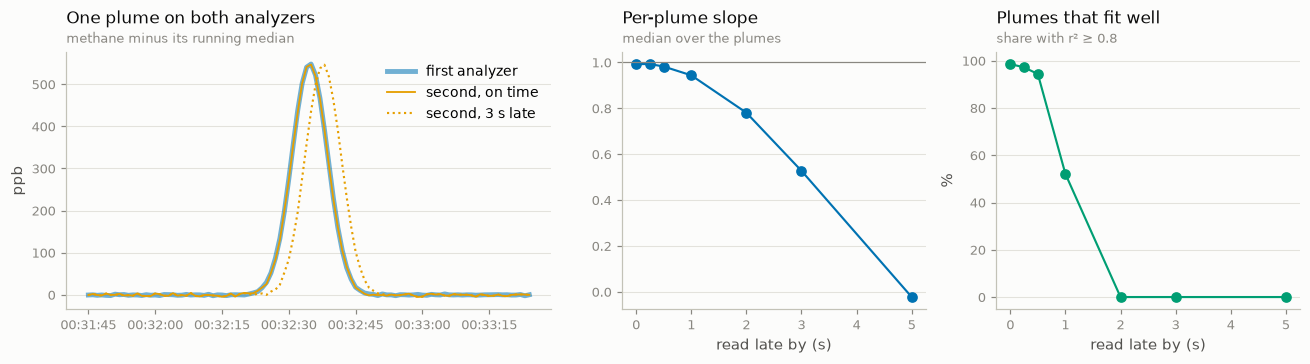

In [4]:
# Figure only.
tallest = max(plumes, key=lambda p: ref[p[0] : p[1]].max())
window = slice(tallest[0] - pd.Timedelta("40s"), tallest[1] + pd.Timedelta("40s"))
on_time, three_late = read_late(0), read_late(3)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.6, 1, 1]})
axes[0].plot(ref[window].index, ref[window], color=C1, lw=3.2, alpha=0.55, label="first analyzer")
axes[0].plot(on_time[window].index, on_time[window], color=C2, lw=1.2, label="second, on time")
axes[0].plot(
    three_late[window].index, three_late[window], color=C2, ls=":", label="second, 3 s late"
)
clock(axes[0], "%H:%M:%S")
finish(
    axes[0], "One plume on both analyzers", "methane minus its running median", "ppb", legend=True
)
axes[1].plot(cost.index, cost["median slope"], "o-", color=C1)
axes[1].axhline(1, color=MUTED, lw=0.8)
finish(axes[1], "Per-plume slope", "median over the plumes", None, "read late by (s)")
axes[2].plot(cost.index, 100 * cost["plumes with r² ≥ 0.8"], "o-", color=C3)
finish(axes[2], "Plumes that fit well", "share with r² ≥ 0.8", "%", "read late by (s)")
fig.tight_layout()
plt.show()

Both give way within a plume's width. With plumes a few seconds wide, half a
second costs a few of the fits that hold (94 % fit well, against 99 %), a whole second
half of them, two seconds all of them, and the slope reads lower with every
second. A shift measured to the nearest whole second (§3) leaves at most half
a second, which is cheap here; one a whole second off is not. On the real 2024
van a similar measurement (Aeris against Picarro on the 08-05 drive, events of
at least five Picarro readings, 2 s apart, above 30 ppb) kept 69 % of events
fitting well aligned, 31–50 % at 1 s, 4–12 % at 2 s (`METHODS.md` §12.1); its
cost below a second is unmeasured, since the Picarro writes every 2 s. There
the aligned slope is 0.84, not 1: two analyzers of one gas need not agree on
scale even with their clocks right, which is a calibration question, not a
clock one. Cross-instrument ratios need clocks right to within about half a
second, which a whole-second resolution leaves at worst.

**Try it.** Set `PLUME_SIGMA = "12s"`: plumes three times wider hold a 3 s
error far better, because a few seconds is now a small part of each. The slope
at 3 s stays near 1 (0.94, against 0.53) and about a quarter of the plumes
still fit well, against none. Even aligned, only 83 % fit well: a wide
plume clears "five seconds above 20 ppb" while barely rising above it, and
such weak plumes swing about 11 ppb inside their run against the second
analyzer's 2 ppb of noise.

---
## §2 The correction table, applied

The generator writes the campaign of §1 to files the way a wrong clock would:
the analyzer `fast` runs 7 s ahead for the first hour (its shift −7 s), then
steps to 19 s ahead (−19 s); `slow` runs 4 s behind throughout (+4 s); `ref`
keeps the reference clock. The exporter also writes the **correction table**
that undoes it. Each row is a stretch of one instrument *on its recorded
clock* and the **shift** added to its times, corrected = recorded + shift:
the same numbers the archive was written with.

Ingestion applies the table to each file as it is read, before the file's
cells are built, so every later stage sees corrected times (`METHODS.md`
§12.3). Below, the same archive is ingested without the table and with it.

In [5]:
# ---- PARAMETERS (section 2) ----
FAST_BEFORE = -7  # the shift 'fast' needs before its step (it runs 7 s ahead); fractions allowed
FAST_AFTER = -19  # ... and after it: at most FAST_BEFORE (a clock set back here would write
#                   the same times twice, which the exporter refuses: METHODS.md §12.3)
STEP = "2026-01-01T01:00:00Z"  # when 'fast' steps
SLOW = 4  # the shift 'slow' needs (positive: it runs behind)
ROWS = "all"  # which rows of the table to declare: "all", or "first" alone

In [6]:
start_section("§2")
setup_logging(logging.WARNING)
END = "2026-01-01T03:00:00Z"
shifts = (
    ("fast", "2026-01-01T00:00:00Z", STEP, FAST_BEFORE),
    ("fast", STEP, END, FAST_AFTER),
    ("slow", "2026-01-01T00:00:00Z", END, SLOW),
)
air, manifest, exported = archive(shifts)

# The exporter writes shifts in nanoseconds; rewritten here as a person would
# write them, which is also how the survey writes its own tables.
rows = read_clock_corrections([exported])
declared = rows if ROWS == "all" else rows[:1]
table = write_clock_corrections(declared, Path(tempfile.mkdtemp()) / "clock_corrections.csv")
print(table.read_text())

as_written = ingest_campaign(manifest)
corrected = ingest_campaign(manifest.model_copy(update={"clock_corrections": (table,)}))


def still_needs(streams, name):
    """Return the shift each reading still needs: seconds from its time to its true time."""
    got = streams[name]["time"].values.astype("datetime64[ns]")
    true = air.streams[name]["time"].values.astype("datetime64[ns]")
    return (true - got) / np.timedelta64(1, "s")


true_fast = pd.DatetimeIndex(air.streams["fast"]["time"].values)
expected_fast = np.where(true_fast < pd.Timestamp(STEP).tz_localize(None), FAST_BEFORE, FAST_AFTER)
check(
    "§2 as written, each reading needs exactly the shift its archive was written with",
    np.array_equal(still_needs(as_written, "fast"), expected_fast)
    and np.all(still_needs(as_written, "slow") == SLOW),
    f"'fast' {FAST_BEFORE:+g} s then {FAST_AFTER:+g} s, 'slow' {SLOW:+g} s",
)


def held_by(name):
    """Which of an instrument's readings a declared row holds, by their recorded times."""
    recorded = as_written[name]["time"].values.astype("datetime64[ns]").astype("int64")
    held = np.zeros(len(recorded), bool)
    for row in declared:
        held |= (row.instrument == name) & (recorded >= row.start_ns) & (recorded < row.end_ns)
    return held


held = held_by("fast")
check(
    "§2 with the table, every reading a row holds is on its true time, and only those",
    np.all(still_needs(corrected, "fast")[held] == 0)
    and np.array_equal(still_needs(corrected, "fast")[~held], expected_fast[~held]),
    f"{held.mean():.0%} of 'fast' held",
)
shares = {name: corrected[name].attrs["tsara_clock_uncorrected_share"] for name in ("fast", "slow")}
check(
    "§2 each stream records the share of its readings no row held, all of them if it has no row",
    all(np.isclose(shares[name], 1 - held_by(name).mean()) for name in shares),
    ", ".join(f"'{name}' {share:.1%}" for name, share in shares.items()),
)
ref_clock = {key: value for key, value in corrected["ref"].attrs.items() if "clock" in key}
check(
    "§2 the reference clock's instrument is left alone and says it keeps the reference clock",
    np.all(still_needs(corrected, "ref") == 0)
    and ref_clock == {"tsara_reference_clock": "ref", "tsara_clock_uncorrected_share": 0.0},
)
print()
print("'fast' records:", corrected["fast"].attrs["tsara_clock_corrections"])

instrument,start,end,shift,shift_end,reference_clock,provenance,reason
fast,2026-01-01T00:00:07Z,2026-01-01T01:00:07Z,-7s,,ref,declared,exported clock error
fast,2026-01-01T01:00:19Z,2026-01-01T03:00:19Z,-19s,,ref,declared,exported clock error
slow,2025-12-31T23:59:56Z,2026-01-01T02:59:56Z,4s,,ref,declared,exported clock error

  ✔ §2 as written, each reading needs exactly the shift its archive was written with   ['fast' -7 s then -19 s, 'slow' +4 s]
  ✔ §2 with the table, every reading a row holds is on its true time, and only those   [100% of 'fast' held]
  ✔ §2 each stream records the share of its readings no row held, all of them if it has no row   ['fast' 0.0%, 'slow' 0.0%]
  ✔ §2 the reference clock's instrument is left alone and says it keeps the reference clock

'fast' records: 2026-01-01T00:00:07Z/2026-01-01T01:00:07Z shift -7 s (moved earlier) onto ref (declared; exported clock error); 2026-01-01T01:00:19Z/2026-01-01T03:00:19Z shift -19 s (moved earlier) onto ref (declared; e

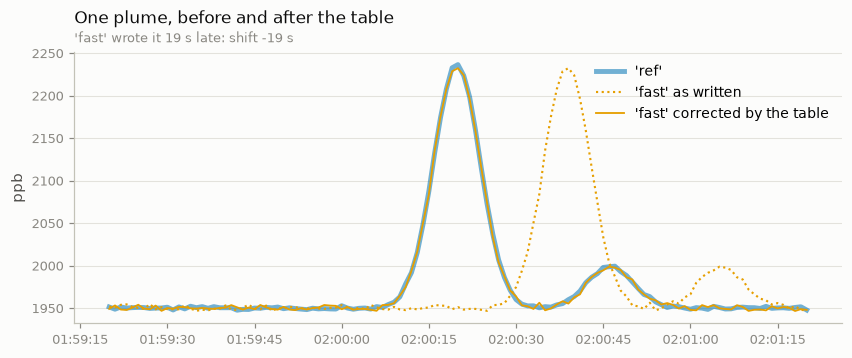

In [7]:
# Figure only: the tallest plume after the step, on the three clocks.
truth_ref = air.streams["ref"]["ch4"].to_series()
after = truth_ref[pd.Timestamp(STEP).tz_localize(None) :]
peak = after.idxmax()
window = slice(peak - pd.Timedelta("60s"), peak + pd.Timedelta("60s"))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(truth_ref[window].index, truth_ref[window], color=C1, lw=3.2, alpha=0.55, label="'ref'")
written = as_written["fast"]["ch4"].to_series()[window]
fixed = corrected["fast"]["ch4"].to_series()[window]
ax.plot(written.index, written, color=C2, ls=":", label="'fast' as written")
ax.plot(fixed.index, fixed, color=C2, lw=1.2, label="'fast' corrected by the table")
clock(ax, "%H:%M:%S")
finish(
    ax,
    "One plume, before and after the table",
    f"'fast' wrote it {-FAST_AFTER:g} s late: shift {FAST_AFTER:+g} s",
    "ppb",
    legend=True,
)
plt.show()

The table is short, readable and exact: a person can check every row of it,
which is why the survey below writes one rather than applying what it
measures. At the defaults `fast`'s two rows leave 12 s between them, 01:00:07
to 01:00:19 on its recorded clock: a clock that jumps 12 s forward records
nothing in those seconds, so no row needs them. Readings no row holds keep
their recorded times, and ingestion says so twice: a warning naming the
stretches, and the share in the stream's `tsara_clock_uncorrected_share`. An
instrument the table has no row for at all is warned about the same way and
recorded as wholly uncorrected, while `ref`, whose clock the table puts the
others on, says it keeps the reference clock.

**Try it.** Set `ROWS = "first"`: only `fast`'s hour before the step is
declared, and `slow`'s row goes too. One warning lists `fast`'s stretch after
the step: 60 % of its readings uncorrected, still needing −19 s, while the
rest are right. Another says the table has no row for `slow`: all its readings
keep their 4 s error, and its share is 100 %.

---
## §3 One segment's shift

The survey measures a shift one segment at a time, from the plumes two
instruments share (`METHODS.md` §12.4). On the archive of §2, as written:

1. each instrument's methane is put on **whole seconds** (each time floored,
   the first reading of each second kept), so a 1 s and a 2 s analyzer can be
   compared second by second without interpolating a gas;
2. its centred **running median is removed**, leaving the **wiggles**: the
   plumes without the slow background, so that on a real record swings the two
   instruments do not share cannot decide the correlation;
3. the **whole-second peak** is the shift s, within the search, at which
   `fast`'s wiggles at t correlate best with `ref`'s at t + s: what `fast`
   records at t, `ref` records at t + s. `fast` shows the air later, so its
   shift is negative;
4. the **shift** is then measured again on the readings' own cells, at
   multiples of the **resolution** within 2 s of that peak: the peak says which
   second the shift falls in, the cells say where inside it.

Steps 1 to 3 are compared with a plain loop written from their definition; the
shift, with the shift the archive was written to need, here −7.3 s, not a
whole number of seconds.

In [8]:
# ---- PARAMETERS (section 3) ----
SEGMENT_START = "2026-01-01T00:30:00Z"  # the half hour to measure
SEARCH = 60  # seconds searched either way
RUNNING_MEDIAN = 121  # seconds of the running median removed
FAST_SHIFT = -7.3  # the shift 'fast' needs in the first hour (-19 after): it runs 7.3 s ahead
RESOLUTION = "0.1s"  # the step the shift is measured in

In [9]:
start_section("§3")
shifts = (
    ("fast", "2026-01-01T00:00:00Z", "2026-01-01T01:00:00Z", FAST_SHIFT),
    ("fast", "2026-01-01T01:00:00Z", "2026-01-01T03:00:00Z", -19),
    ("slow", "2026-01-01T00:00:00Z", "2026-01-01T03:00:00Z", 4),
)
air, manifest, _ = archive(shifts)
streams = ingest_campaign(manifest)
first = int(pd.Timestamp(SEGMENT_START).timestamp())
stop = first + 1800

own = seconds_series(streams["fast"], "ch4", running_median_s=RUNNING_MEDIAN)
partner = seconds_series(streams["ref"], "ch4", running_median_s=RUNNING_MEDIAN)
peak = pooled_shift(
    [(own, partner)], first, stop, search_s=SEARCH, min_pairs=300, min_r=0.6, tolerance_s=2.0
)
print(f"whole seconds: peak at {peak.shift_s:+.0f} s, r {peak.r:.4f}, on {peak.n_pairs} pairs")

# Step 4: the shift again on the readings' own cells, at multiples of the
# resolution within 2 s of the peak. Each analyzer's noise is declared in the
# manifest, so it is taken out of the correlation first (METHODS.md §12.4).
fine, at_edge, removed, refined = refined_shift(
    [
        (
            cell_series(streams["fast"], "ch4", running_median_s=RUNNING_MEDIAN),
            cell_series(streams["ref"], "ch4", running_median_s=RUNNING_MEDIAN),
        )
    ],
    first * 1_000_000_000,
    stop * 1_000_000_000,
    coarse_s=peak.shift_s,
    resolution_ns=pd.Timedelta(RESOLUTION).value,
    min_pairs=300,
)
print(
    f"on the readings' own cells, to {RESOLUTION}: shift {fine:+.2f} s"
    f" (measured to the resolution: {'yes' if refined else 'no, the whole-second peak'};"
    f" declared noise removed: {'yes' if removed else 'no'})"
)

# The plain loops, on enough of each record to cover the segment and the search.
margin = pd.Timedelta(seconds=SEARCH + RUNNING_MEDIAN)
around = slice(
    pd.Timestamp(SEGMENT_START).tz_localize(None) - margin,
    pd.Timestamp(SEGMENT_START).tz_localize(None) + pd.Timedelta("30min") + margin,
)
ref_own = reference_wiggles(streams["fast"].sel(time=around), "ch4", RUNNING_MEDIAN)
ref_partner = reference_wiggles(streams["ref"].sel(time=around), "ch4", RUNNING_MEDIAN)
plain_shift, plain_r = reference_shift(ref_own, ref_partner, first, stop, SEARCH, 300)

inside = [s for s in range(first, stop) if s in ref_own]
package = np.array([own.values[s - own.first_s] for s in inside])
check(
    "§3 TSARA's wiggles equal the plain loop's at every second of the segment",
    np.allclose(package, [ref_own[s] for s in inside], equal_nan=False),
    f"{len(inside)} seconds",
)
check(
    "§3 TSARA's shift and r equal the plain loop's",
    peak.shift_s == plain_shift and np.isclose(peak.r, plain_r),
    f"{plain_shift:+d} s, r {plain_r:.4f}",
)
segment_start = pd.Timestamp(SEGMENT_START)
segment_end = segment_start + pd.Timedelta("30min")
step = pd.Timestamp("2026-01-01T01:00:00Z")
# The nearest multiple of the resolution: within half a step (below about
# 0.05 s the noise decides, not the lattice).
allowed = max(pd.Timedelta(RESOLUTION).total_seconds() / 2, 0.05) + 1e-9
claim = (
    "§3 on the readings' own cells the shift is the nearest multiple of the resolution"
    " to the written one"
)
if segment_end <= step or segment_start >= step:
    written = FAST_SHIFT if segment_end <= step else -19
    check(
        claim,
        abs(fine - written) <= allowed,
        f"written {written:+g} s, measured {fine:+.2f} s, allowed ±{allowed:.2g} s",
    )
else:
    print(
        f"  – skipped: {claim[3:]}. This segment spans 'fast''s step at 01:00,"
        " so the archive was written with two shifts in it"
    )

whole seconds: peak at -7 s, r 0.9983, on 1800 pairs
on the readings' own cells, to 0.1s: shift -7.30 s (measured to the resolution: yes; declared noise removed: yes)


  ✔ §3 TSARA's wiggles equal the plain loop's at every second of the segment   [1800 seconds]
  ✔ §3 TSARA's shift and r equal the plain loop's   [-7 s, r 0.9983]
  ✔ §3 on the readings' own cells the shift is the nearest multiple of the resolution to the written one   [written -7.3 s, measured -7.30 s, allowed ±0.05 s]


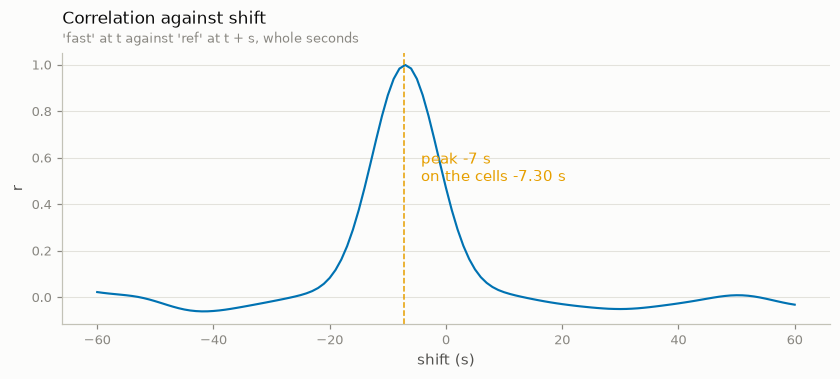

In [10]:
# Figure only.
curve = []
for shift in range(-SEARCH, SEARCH + 1):
    x = own.window(first, stop)
    y = partner.window(first + shift, stop + shift)
    ok = np.isfinite(x) & np.isfinite(y)
    curve.append(np.corrcoef(x[ok], y[ok])[0, 1] if ok.sum() >= 300 else np.nan)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(range(-SEARCH, SEARCH + 1), curve, color=C1)
ax.axvline(fine, color=C2, lw=1, ls="--")
ax.text(fine + 3, 0.5 * peak.r, f"peak {peak.shift_s:+.0f} s\non the cells {fine:+.2f} s", color=C2)
finish(
    ax,
    "Correlation against shift",
    "'fast' at t against 'ref' at t + s, whole seconds",
    "r",
    "shift (s)",
)
plt.show()

The whole-second curve has one sharp peak, at the second the shift falls in,
because the plumes are narrow: a few seconds off and they no longer overlap. A
best shift at the edge of the search is never decided, since the true one may
lie beyond it. Whole seconds cannot say where inside its second the shift
lies (each reading's time was floored to put it there), so the shift is
measured again on the readings' own cells, and comes back as the −7.3 s the
archive was written to need. This campaign's background is flat (1950 ppb, the
same for every instrument), so the running median takes away a constant: here
it matters only when it is too short, as the first Try-it shows. On a real
record it is there for slow swings two instruments do not share, which is a
claim to be measured on the SLC-SOS van (`METHODS.md` §12.6, §12.7).

**Try it.** Set `RUNNING_MEDIAN = 11`: a median over 11 s follows a plume
rather than the background beneath it, so it takes much of each plume away.
The peak stays at −7 s but its r falls (0.92, against 1.00), and with it the
margin a segment has above the 0.6 it needs to be decided.

**Try it.** Set `RESOLUTION = "1s"` and `FAST_SHIFT = -7.7`: the shift comes
back as −8 s, the nearest whole second.

---
## §4 The survey: every segment, the chain, the rows

`survey_clocks` measures every tier of every instrument on every segment, on
one grid of segments shared by all of them (`METHODS.md` §12.4). Its settings
live in a survey YAML of their own (`examples/configs/survey_example.yaml`);
here they are built in the setup cell: `fast` is measured against `ref`, and
`slow` against `fast` first, with `ref` directly as a backup tier that checks
it. `slow`'s shift onto `fast` plus `fast`'s shift onto `ref` is its shift onto
the **reference clock**: the chain.

Consecutive segments whose shifts agree become one row of the table; a jump is a
**clock step**, and the two rows meet at the one gap in the readings the step
explains (the hole a clock leaves when it jumps forward, else a single logging
stop) rather than at a segment edge; failing both, at the segment edges.

In [11]:
# ---- PARAMETERS (section 4) ----
SEGMENT = "30min"  # one shift per segment of this length
MIN_R = 0.6  # the correlation a segment needs to be decided
TOLERANCE = "2s"  # shifts agreeing within this are one row

In [12]:
start_section("§4")
shifts = (
    ("fast", "2026-01-01T00:00:00Z", "2026-01-01T01:00:00Z", -7),
    ("fast", "2026-01-01T01:00:00Z", "2026-01-01T03:00:00Z", -19),
    ("slow", "2026-01-01T00:00:00Z", "2026-01-01T03:00:00Z", 4),
)
air, manifest, exported = archive(shifts)
streams = ingest_campaign(manifest)
survey = survey_clocks(streams, survey_settings(SEGMENT, MIN_R, TOLERANCE))

columns = [
    "instrument",
    "start",
    "tier",
    "partner",
    "shift_onto_partner_s",
    "shift_onto_reference_s",
    "status",
]
print(survey.segments[columns].to_string(index=False))
print("\nrows:")
for row in survey.rows:
    print(" ", row.instrument, row.describe())
print("\nfaults:")
print(survey.faults.to_string(index=False) if len(survey.faults) else "  none")
print()

truth = {(r.instrument, r.shift_ns) for r in read_clock_corrections([exported])}
check(
    "§4 the survey's shifts are the ones the archive was written to need",
    {(r.instrument, r.shift_ns) for r in survey.rows} == truth,
)
fast_rows = [r for r in survey.rows if r.instrument == "fast"]
times = streams["fast"]["time"].values.astype("datetime64[ns]").astype("int64")
after_hole = int(times[times >= pd.Timestamp("2026-01-01T01:00:19").value][0])
check(
    "§4 'fast''s two rows meet at the first reading after its step, not at a segment edge",
    len(fast_rows) == 2 and fast_rows[0].end_ns == fast_rows[1].start_ns == after_hole,
    pd.Timestamp(after_hole).strftime("%H:%M:%S"),
)
slow = survey.segments[
    (survey.segments.instrument == "slow") & (survey.segments.status == "decided")
]
check(
    "§4 'slow', measured against 'fast', reaches the reference clock through the chain",
    len(slow) > 0 and (slow.shift_onto_reference_s == 4).all(),
    f"{len(slow)} decided segments at +4 s",
)
# The backup tier: 'slow' measured against 'ref' directly, beside the shift the
# chain gives it ('slow' onto 'fast', plus 'fast''s own shift onto 'ref').
m = survey.measurements
backup = (
    m[(m.instrument == "slow") & (m.tier == 2) & m.decided].set_index("start").shift_onto_partner_s
)
chained = survey.segments[survey.segments.instrument == "slow"].set_index("start")
side = pd.DataFrame(
    {
        "against 'fast'": chained.shift_onto_partner_s,
        "chained to 'ref'": chained.shift_onto_reference_s,
        "backup, against 'ref'": backup,
        "status": chained.status,
    }
).dropna(subset=["chained to 'ref'", "backup, against 'ref'"], how="all")
print("\n'slow', segment by segment:")
print(side.to_string())
print()

# A segment of 'slow' whose search reaches across 'fast''s step compares 'slow'
# with a partner that changed clock part-way through: the chain is not to be
# trusted there, which is what the backup tier is for. Everywhere else the two
# routes should agree.
boundary = pd.Timestamp(fast_rows[0].end_ns)
search = pd.Timedelta(survey.config.search)
starts = pd.to_datetime(pd.Series(side.index, index=side.index)).dt.tz_localize(None)
away = (starts - search > boundary) | (starts + pd.Timedelta(SEGMENT) + search <= boundary)
gap = (side["backup, against 'ref'"] - side["chained to 'ref'"]).abs()
tolerance = pd.Timedelta(TOLERANCE).total_seconds()
check(
    "§4 its backup tier agrees with the chain wherever 'fast' keeps one clock",
    away.sum() > 0 and gap[away].notna().all() and (gap[away] <= tolerance).all(),
    f"{int(away.sum())} segment(s), largest difference {gap[away].max():g} s",
)
# Where 'slow''s first tier cannot decide a segment, its backup tier decides it.
first_tier = m[(m.instrument == "slow") & (m.tier == 1)].set_index("start").decided
backup_only = first_tier.index[~first_tier & first_tier.index.isin(backup.index)]
check(
    "§4 where 'slow''s first tier cannot decide a segment, its backup tier does",
    all(chained.loc[k, "status"] == "decided" and chained.loc[k, "tier"] == 2 for k in backup_only),
    f"{len(backup_only)} segment(s)",
)

instrument                start  tier partner  shift_onto_partner_s  shift_onto_reference_s    status
      fast 2026-01-01T00:00:00Z     1     ref                  -7.0                    -7.0   decided
      fast 2026-01-01T00:30:00Z     1     ref                  -7.0                    -7.0   decided
      fast 2026-01-01T01:00:00Z     1     ref                 -19.0                   -19.0   decided
      fast 2026-01-01T01:30:00Z     1     ref                 -19.0                   -19.0   decided
      fast 2026-01-01T02:00:00Z     1     ref                 -19.0                   -19.0   decided
      fast 2026-01-01T02:30:00Z  <NA>                           NaN                     NaN too short
      slow 2025-12-31T23:30:00Z  <NA>                           NaN                     NaN too short
      slow 2026-01-01T00:00:00Z     1    fast                  11.0                     4.0   decided
      slow 2026-01-01T00:30:00Z     1    fast                  11.0               

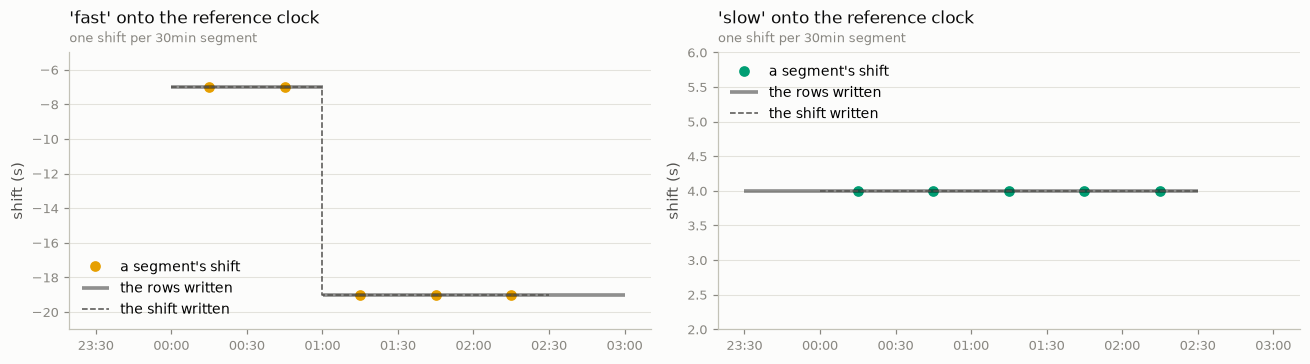

In [13]:
# Figure only.
truth_line = {
    "fast": pd.Series(
        [-7, -7, -19, -19],
        index=pd.to_datetime(
            ["2026-01-01 00:00", "2026-01-01 01:00", "2026-01-01 01:00", "2026-01-01 02:30"]
        ),
    ),
    "slow": pd.Series([4, 4], index=pd.to_datetime(["2026-01-01 00:00", "2026-01-01 02:30"])),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharex=True)
for ax, name, color in zip(axes, ("fast", "slow"), (C2, C3)):
    shift_panel(ax, survey, name, truth_line[name], color)
    finish(
        ax,
        f"'{name}' onto the reference clock",
        f"one shift per {SEGMENT} segment",
        "shift (s)",
        legend=True,
        loc="lower left" if name == "fast" else "upper left",
    )
fig.tight_layout()
plt.show()

Each point is one segment's shift onto the reference clock, the solid lines
are the rows the survey wrote, and the dashed line is the shift the archive
was written to need: the three are one number, so on the right clock they lie
on top of each other. The survey wrote one row for `slow` and two for `fast`,
and named the step between them. The table of `slow`'s segments shows the
backup tier at work: +11 s onto `fast` before the step and +23 s after, plus
`fast`'s own shift (−7 s, then −19 s), is +4 s onto the reference clock
throughout, and the backup tier, measured against `ref` directly, says +4 s
in every segment too. The grid's two end segments, 23:30 and 02:30, hold only
seconds of readings (`slow`'s first 4 s, before midnight on its slow clock, and
`fast`'s last 19 s), too few to measure (`too short`, tier `<NA>`); they are
not undecided, and the rows reach over them.

**Try it.** Set `SEGMENT = "10min"`: three times as many segments, the same
rows, and the step still on the reading after the hole, because the boundary
follows the readings, not the segment grid. One thing more appears in
`slow`'s table: at 00:50 its first tier cannot decide. A 10-minute segment
holds 300 of `slow`'s 2 s readings, exactly the 300 paired seconds a segment's
best shift needs, and `fast`'s 12 s hole at its step costs the true shift
two of them (its r is still 0.99; the measurements table keeps both). So the
backup tier against `ref` decides that segment, at +4 s, and the rows do not
move.

---
## §5 What the survey names instead of fitting

A clock does not only jump. Here three instruments are built by hand from one
sequence of plumes, each recording them on a clock that misbehaves in its own
way, against `ref` on the right one (`METHODS.md` §12.5):

* `drifting` gains a few seconds an hour, smoothly;
* `odd` is 4 s late, except for one segment in which its clock really slips
  to 12 s late, which the survey cannot tell from a coincidence of plumes;
* `gappy` is 5 s late, but its methane is missing for ten minutes while it
  logs other things.

The survey turns each into rows and names what it saw.

In [14]:
# ---- PARAMETERS (section 5) ----
DRIFT_PER_HOUR = 6.0  # seconds 'drifting' gains each hour (its shift falls by this)
OUTLIER = -12.0  # the shift of 'odd''s one strange segment, where the rest are -4 s
TOLERANCE = "2s"  # shifts agreeing within this are one row
RESOLUTION = "1s"  # the step each segment's shift is measured in

In [15]:
start_section("§5")
N = 5400  # an hour and a half of 1 s readings: nine 10-minute segments
rng = np.random.default_rng(3)
plumes = np.zeros(N + 200)
for centre in rng.choice(N, size=N // 30, replace=False):
    plumes += rng.lognormal(3, 0.5) * np.exp(-0.5 * ((np.arange(N + 200) - centre) / 3.0) ** 2)


def recorded(shift, seed, missing=None):
    """Return readings of the plume at true second t, written at t - shift(t).

    So adding the shift puts each reading back on its true time.
    """
    t = np.arange(N, dtype=float)
    values = plumes[:N] + np.random.default_rng(seed).normal(0, 0.3, N)
    if missing is not None:
        values[(t >= missing[0]) & (t < missing[1])] = np.nan
    times = START + pd.to_timedelta(t - shift(t), unit="s")
    order = np.argsort(np.asarray(times))
    return xr.Dataset(
        {"ch4": ("time", values[order]), "other": ("time", np.ones(N))},
        coords={"time": np.asarray(times)[order]},
    )


drift = lambda t: -(1.0 + DRIFT_PER_HOUR * t / 3600)  # noqa: E731
odd = lambda t: np.where((t >= 1800) & (t < 2400), OUTLIER, -4.0)  # noqa: E731
streams = {
    "ref": recorded(lambda t: 0.0 * t, 1),
    "drifting": recorded(drift, 2),
    "odd": recorded(odd, 3),
    "gappy": recorded(lambda t: -5.0 + 0.0 * t, 4, missing=(3000, 3600)),
}
config = SurveyConfig.model_validate(
    {
        "reference_clock": "ref",
        "tracers": {
            name: [{"partner": "ref", "pairs": [["ch4", "ch4"]]}]
            for name in streams
            if name != "ref"
        },
        "segment": "10min",
        "search": "30s",
        "min_pairs": 200,
        "running_median": "61s",
        "tolerance": TOLERANCE,
        "resolution": RESOLUTION,
    }
)
survey = survey_clocks(streams, config)
for row in survey.rows:
    print(" ", row.instrument, row.describe())
print()
print(survey.faults.to_string(index=False))
print()


def rows_of(name):
    """Return the survey's rows for one instrument."""
    return [r for r in survey.rows if r.instrument == name]


drifting = rows_of("drifting")
# Within half a step of the resolution; below about 0.05 s the noise decides.
allowed = max(pd.Timedelta(RESOLUTION).total_seconds() / 2, 0.05) + 1e-9
if len(drifting) == 1 and drifting[0].shift_end_ns is not None:
    start_s = (drifting[0].start_ns - START.value) / 1e9
    end_s = (drifting[0].end_ns - START.value) / 1e9
    written = (drifting[0].shift_ns / 1e9, drifting[0].shift_end_ns / 1e9)
    check(
        "§5 a slow drift is one row whose shift runs within half the resolution of the truth",
        abs(written[0] - drift(start_s)) <= allowed and abs(written[1] - drift(end_s)) <= allowed,
        f"{written[0]:+.2f} s to {written[1]:+.2f} s, truth {drift(start_s):+.2f} s to "
        f"{drift(end_s):+.2f} s, allowed ±{allowed:.2g} s",
    )
else:
    check(
        "§5 a drift faster than the tolerance per segment is named a fast drift",
        (survey.faults.kind == "fast drift").any(),
    )
odd_status = survey.segments[survey.segments.instrument == "odd"].status.tolist()
check(
    "§5 one segment against two agreeing neighbours is set aside, and the row runs on",
    "outlier" in odd_status and len(rows_of("odd")) == 1 and rows_of("odd")[0].shift_ns == -4e9,
)
undecided = survey.faults[
    (survey.faults.instrument == "gappy") & (survey.faults.kind == "undecided")
]
check(
    "§5 a stretch with readings but no tracer ends the row and is named",
    len(rows_of("gappy")) == 2 and list(undecided.start) == ["2026-01-01T00:50:00Z"],
    "00:50 to 01:00 left uncorrected",
)
check(
    "§5 every fault named is one of the kinds the survey knows",
    set(survey.faults.kind) <= set(FAULT_KINDS),
)

# What the outlier rule's bet costs here: 'odd''s clock really did slip, so the
# readings of that segment take the row's -4 s.
true_s = np.arange(N, dtype=float)
recorded_ns = np.asarray(START + pd.to_timedelta(true_s - odd(true_s), unit="s")).astype(
    "datetime64[ns]"
)
applied, _ = shift_at(rows_of("odd"), recorded_ns.astype("int64"))
wrong = np.abs(applied / 1e9 - odd(true_s)) > 1.0
print(
    f"\n'odd': {wrong.sum()} of {N} readings corrected more than 1 s wrong, "
    f"by {np.abs(applied / 1e9 - odd(true_s)).max():g} s at most"
)

  drifting 2026-01-01T00:00:00Z/2026-01-01T01:40:00Z shift -0.905556 s to -11.2389 s (moved earlier) onto ref (measured; clock survey: 9 segments, tier 1, shifts -9 to -1 s)
  odd 2026-01-01T00:00:00Z/2026-01-01T01:40:00Z shift -4 s (moved earlier) onto ref (measured; clock survey: 8 segments, tier 1, shifts -4 to -4 s)
  gappy 2026-01-01T00:00:00Z/2026-01-01T00:50:00Z shift -5 s (moved earlier) onto ref (measured; clock survey: 5 segments, tier 1, shifts -5 to -5 s)
  gappy 2026-01-01T01:00:00Z/2026-01-01T01:40:00Z shift -5 s (moved earlier) onto ref (measured; clock survey: 3 segments, tier 1, shifts -5 to -5 s)

instrument        kind                start                  end                                      detail
  drifting clock drift 2026-01-01T00:00:00Z 2026-01-01T01:30:00Z shift -0.91 s to -11.24 s, -6.20 s per hour
       odd     outlier 2026-01-01T00:30:00Z 2026-01-01T00:40:00Z              shift -12 s against neighbours
     gappy   undecided 2026-01-01T00:50:00Z 2026-0

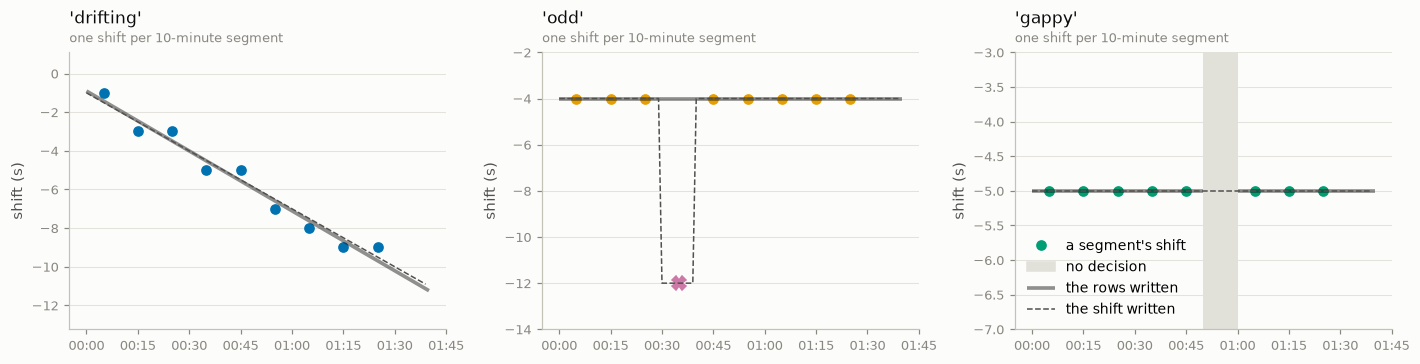

In [16]:
# Figure only.
t = np.arange(0, N + 600, 60.0)
truths = {
    "drifting": pd.Series(drift(t), index=START + pd.to_timedelta(t, unit="s")),
    "odd": pd.Series(odd(t), index=START + pd.to_timedelta(t, unit="s")),
    "gappy": pd.Series(-5.0, index=START + pd.to_timedelta(t, unit="s")),
}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharex=True)
for ax, (name, truth), color in zip(axes, truths.items(), (C1, C2, C3)):
    shift_panel(ax, survey, name, truth, color)
    finish(
        ax,
        f"'{name}'",
        "one shift per 10-minute segment",
        "shift (s)",
        legend=name == "gappy",
        loc="lower left",
    )
fig.tight_layout()
plt.show()

`drifting` becomes one row with a `shift_end`: the shift runs linearly across
it, as a drifting clock's error does. Each segment's shift is measured to the
resolution, here a whole second, and this clock's true shift at the middle of
every segment is a half second (−1.5, −2.5, …), so each point sits exactly half
a second above or below the true line. The row's line through them, evaluated
at the row's own ends (which here reach over the record's short last segment),
still lands within a quarter second of the truth at both ends, and its rate
comes out 6.2 s an hour against the 6.0 written. `odd`'s strange segment is set aside
against its two agreeing neighbours, and stays inside the row around it. The
survey cannot tell a clock that slips for one segment from a coincidence of
plumes, and bets on the coincidence, since one segment against two is more
likely that than two clock steps in a row. Here the slip is real, so that
segment's 600 readings are corrected 8 s wrong (printed above): the `outlier`
fault is where a reviewer looks. `gappy`'s ten minutes without methane end its
first row (`too few pairs`: nothing to pair there); the survey writes nothing
for them, so ingestion will leave them as recorded and say so.

**Try it.** Set `RESOLUTION = "0.1s"`: each point now sits within 0.1 s of
the true line, and the row lands within 0.03 s of the truth at both ends, at
5.99 s an hour.

**Try it.** Set `TOLERANCE = "0.5s"`: `drifting` now gains more than the
tolerance between segments, so instead of one drifting row it gets six short
ones of one or two segments, a clock step between each, and the survey names
the run of same-signed steps a *fast drift* (a shorter segment, or a larger
tolerance, resolves it).

---
## §6 The loop closed

What the survey is for: measure a campaign ingested as written, save what it
found, read the table, name it in the manifest, ingest again. `save_clock_survey`
writes the table beside the evidence for every row (the measurements, the
segments, the faults, the settings), in a bundle's `survey/` directory.

Surveyed again, a corrected campaign is an **after-check**: every shift should
be zero, no rows are derived from streams that already carry a table, and each
stream's `after-check` fault states its residuals.

In [17]:
# ---- PARAMETERS (section 6) ----
SEGMENT = "30min"  # one shift per segment of this length

In [18]:
start_section("§6")
shifts = (
    ("fast", "2026-01-01T00:00:00Z", "2026-01-01T01:00:00Z", -7),
    ("fast", "2026-01-01T01:00:00Z", "2026-01-01T03:00:00Z", -19),
    ("slow", "2026-01-01T00:00:00Z", "2026-01-01T03:00:00Z", 4),
)
air, manifest, _ = archive(shifts)
survey = survey_clocks(ingest_campaign(manifest), survey_settings(SEGMENT))

bundle = Path(tempfile.mkdtemp()) / "bundle"
folder = save_clock_survey(survey, bundle)
print("survey/ holds:", sorted(p.name for p in folder.iterdir()), "\n")
print((folder / "clock_corrections.csv").read_text())

back = load_clock_survey(bundle)


def written(row):
    """Every field of a row but where it was read from, which a reload names afresh."""
    return {k: v for k, v in asdict(row).items() if k not in ("source", "line")}


check(
    "§6 a saved survey reloads exactly: its tables, its settings, its rows",
    all(getattr(back, n).equals(getattr(survey, n)) for n in ("measurements", "segments", "faults"))
    and back.config == survey.config
    and [written(r) for r in back.rows] == [written(r) for r in survey.rows],
)

table = folder / "clock_corrections.csv"
corrected = ingest_campaign(manifest.model_copy(update={"clock_corrections": (table,)}))
check(
    "§6 the survey's own table puts every reading of every instrument on its true time",
    all(
        np.array_equal(corrected[n]["time"].values, air.streams[n]["time"].values)
        for n in air.streams
    ),
)
again = survey_clocks(corrected, survey_settings(SEGMENT))
residuals = again.segments.shift_onto_reference_s.dropna()
check(
    "§6 surveyed again, every decided shift is zero and no rows are derived",
    len(residuals) > 0 and (residuals == 0).all() and again.rows == (),
    f"{len(residuals)} segments",
)
print()
print(again.faults[["instrument", "kind", "detail"]].to_string(index=False))

survey/ holds: ['clock_corrections.csv', 'faults.parquet', 'measurements.parquet', 'segments.parquet', 'survey.yaml'] 

instrument,start,end,shift,shift_end,reference_clock,provenance,reason
fast,2026-01-01T00:00:00Z,2026-01-01T01:00:19Z,-7s,,ref,measured,"clock survey: 2 segments, tier 1, shifts -7 to -7 s"
fast,2026-01-01T01:00:19Z,2026-01-01T03:00:00Z,-19s,,ref,measured,"clock survey: 3 segments, tier 1, shifts -19 to -19 s"
slow,2025-12-31T23:30:00Z,2026-01-01T02:30:00Z,4s,,ref,measured,"clock survey: 5 segments, tier 1, shifts +4 to +4 s"

  ✔ §6 a saved survey reloads exactly: its tables, its settings, its rows
  ✔ §6 the survey's own table puts every reading of every instrument on its true time


  ✔ §6 surveyed again, every decided shift is zero and no rows are derived   [10 segments]

instrument        kind                                                                                                                                             detail
      fast after-check the stream carries clock corrections already: measured as an after-check, no rows derived; 5 decided segments, residuals +0 to +0 s, 0 beyond ±2 s
      slow after-check the stream carries clock corrections already: measured as an after-check, no rows derived; 5 decided segments, residuals +0 to +0 s, 0 beyond ±2 s


The manifest here names the table straight from the bundle, which is safe
only because the answer is known. On a real campaign the table is copied
beside the manifest, read and corrected by a person, and the copy is what the
manifest names.

That is the whole of Phase 3.6's machinery: a table declared beside the
manifest and applied as each file is read (§2), and a survey that measures it
from the data (§3–§5) and writes it for a person to review (§6). What comes
next is the real campaign: the SLC-SOS van, read from its analyzers' own logs,
surveyed against its GPS-timed weather station.

---
## Scoreboard

Every check printed above, gathered: each line a claim about TSARA, compared
as it ran against a reference written independently in this notebook or the
shift the archive was written to need.

In [19]:
held = sum(ok for ok, _ in CHECKS.values())
print(f"{held} of {len(CHECKS)} checks hold\n")
for claim, (ok, detail) in CHECKS.items():
    print(f"  {'✔' if ok else '✘'} {claim}" + (f"   [{detail}]" if detail else ""))

19 of 19 checks hold

  ✔ §2 as written, each reading needs exactly the shift its archive was written with   ['fast' -7 s then -19 s, 'slow' +4 s]
  ✔ §2 with the table, every reading a row holds is on its true time, and only those   [100% of 'fast' held]
  ✔ §2 each stream records the share of its readings no row held, all of them if it has no row   ['fast' 0.0%, 'slow' 0.0%]
  ✔ §2 the reference clock's instrument is left alone and says it keeps the reference clock
  ✔ §3 TSARA's wiggles equal the plain loop's at every second of the segment   [1800 seconds]
  ✔ §3 TSARA's shift and r equal the plain loop's   [-7 s, r 0.9983]
  ✔ §3 on the readings' own cells the shift is the nearest multiple of the resolution to the written one   [written -7.3 s, measured -7.30 s, allowed ±0.05 s]
  ✔ §4 the survey's shifts are the ones the archive was written to need
  ✔ §4 'fast''s two rows meet at the first reading after its step, not at a segment edge   [01:00:19]
  ✔ §4 'slow', measured against 